In [ ]:
pip install tensorflow scikit-learn matplotlib pandas pillow

  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl (350.8 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

In [2]:
train_df = pd.read_csv(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cat_train.csv")
val_df   = pd.read_csv(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cat_val.csv")
test_df  = pd.read_csv(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cat_test.csv")

In [3]:
train_df['breed'] = train_df['breed'].astype(str)
val_df['breed']   = val_df['breed'].astype(str)
test_df['breed']  = test_df['breed'].astype(str)
 
NUM_CLASSES = train_df['breed'].nunique()
print(f"Number of classes: {NUM_CLASSES}")
print(train_df['breed'].value_counts())
 
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

Number of classes: 11
breed
Sahiwal              303
Gir                  245
Holstein_Friesian    229
Jersey               138
Hallikar             128
Murrah               117
Red_Sindhi           111
Malnad_gidda          71
Kasargod              66
Amritmahal            64
Surti                 38
Name: count, dtype: int64


In [4]:
# 2. Data generators
#    Images are already resized to 224x224, so we only need
#    MobileNetV2's own preprocessing + light augmentation on train.
# -----------------------------------------------------------------
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)
 
val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)
 
train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='image_path',
    y_col='breed',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=42
)
 
val_gen = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='image_path',
    y_col='breed',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
 
test_gen = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='image_path',
    y_col='breed',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)
 
# Save class index mapping — you will need this at inference time
class_indices = train_gen.class_indices
idx_to_class = {v: k for k, v in class_indices.items()}
print("Class mapping:", class_indices)
 
import json
with open(r"C:\Users\Lenovo\Desktop\CattleBreedClean\class_indices.json", "w") as f:
    json.dump(class_indices, f, indent=2)

Found 1510 validated image filenames belonging to 11 classes.
Found 324 validated image filenames belonging to 11 classes.
Found 324 validated image filenames belonging to 11 classes.
Class mapping: {'Amritmahal': 0, 'Gir': 1, 'Hallikar': 2, 'Holstein_Friesian': 3, 'Jersey': 4, 'Kasargod': 5, 'Malnad_gidda': 6, 'Murrah': 7, 'Red_Sindhi': 8, 'Sahiwal': 9, 'Surti': 10}


In [5]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # freeze base for stage 1
 
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(NUM_CLASSES, activation='softmax')(x)
 
model = Model(inputs=base_model.input, outputs=output)
 
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
 
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,423,371 (9.24 MB)

 Trainable params: 165,387 (646.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [6]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint(
    r"C:\Users\Lenovo\Desktop\CattleBreedClean\best_model_stage1.keras",
    monitor='val_accuracy', save_best_only=True
)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

In [7]:
EPOCHS_STAGE1 = 100
 
history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_STAGE1,
    callbacks=[early_stop, checkpoint, reduce_lr],
    verbose=2   # prints one full line per epoch, no spinner — makes crashes vs early-stop obvious
)

Epoch 1/100
48/48 - 78s - 2s/step - accuracy: 0.4311 - loss: 1.7528 - val_accuracy: 0.5309 - val_loss: 1.3548 - learning_rate: 0.0010
Epoch 2/100
48/48 - 61s - 1s/step - accuracy: 0.6126 - loss: 1.1730 - val_accuracy: 0.6235 - val_loss: 1.1632 - learning_rate: 0.0010
Epoch 3/100
48/48 - 66s - 1s/step - accuracy: 0.6391 - loss: 1.0342 - val_accuracy: 0.6296 - val_loss: 1.1013 - learning_rate: 0.0010
Epoch 4/100
48/48 - 84s - 2s/step - accuracy: 0.6781 - loss: 0.9348 - val_accuracy: 0.6327 - val_loss: 1.0385 - learning_rate: 0.0010
Epoch 5/100
48/48 - 83s - 2s/step - accuracy: 0.7139 - loss: 0.8423 - val_accuracy: 0.6728 - val_loss: 0.9829 - learning_rate: 0.0010
Epoch 6/100
48/48 - 78s - 2s/step - accuracy: 0.7457 - loss: 0.7520 - val_accuracy: 0.6636 - val_loss: 0.9931 - learning_rate: 0.0010
Epoch 7/100
48/48 - 73s - 2s/step - accuracy: 0.7497 - loss: 0.7115 - val_accuracy: 0.6451 - val_loss: 0.9848 - learning_rate: 0.0010
Epoch 8/100
48/48 - 52s - 1s/step - accuracy: 0.7715 - loss: 0

In [8]:
# -----------------------------------------------------------------
# 6. Stage 2: Fine-tune — unfreeze last ~30 layers, train slowly
# -----------------------------------------------------------------
# Unfreeze fewer layers to reduce memory load during fine-tuning.
# If your system has limited RAM, this avoids the massive slowdowns
# (or crashes) caused by too many trainable parameters at once.
base_model.trainable = True
for layer in base_model.layers[:-15]:
    layer.trainable = False
 
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
 
checkpoint2 = ModelCheckpoint(
    r"C:\Users\Lenovo\Desktop\CattleBreedClean\best_model_final.keras",
    monitor='val_accuracy', save_best_only=True, mode='max'
)
 
# IMPORTANT: fresh EarlyStopping instance for stage 2.
# Reusing the same object from stage 1 carries over its internal
# "wait counter" state, causing stage 2 to stop almost immediately.
early_stop_stage2 = EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, mode='max')
reduce_lr_stage2 = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7)
 
# Same logic — high ceiling, EarlyStopping decides the real stop point
EPOCHS_STAGE2 = 100
 
history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_STAGE2,
    callbacks=[early_stop_stage2, checkpoint2, reduce_lr_stage2]
)
 

Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.7477 - loss: 0.7270 - val_accuracy: 0.6883 - val_loss: 0.9016 - learning_rate: 1.0000e-05
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.7854 - loss: 0.6014 - val_accuracy: 0.6975 - val_loss: 0.9070 - learning_rate: 1.0000e-05
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.7940 - loss: 0.5873 - val_accuracy: 0.6944 - val_loss: 0.9083 - learning_rate: 1.0000e-05
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.8126 - loss: 0.5514 - val_accuracy: 0.7006 - val_loss: 0.9063 - learning_rate: 1.0000e-05
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.8166 - loss: 0.5189 - val_accuracy: 0.7099 - val_loss: 0.9053 - learning_rate: 5.0000e-06
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.8166 - loss: 0.5387 - val_accuracy: 0.7160 - val_loss: 0.9002 - learning_rate: 5.0000e-06
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.8199 

In [9]:
# -----------------------------------------------------------------
test_loss, test_acc = model.evaluate(test_gen)
print(f"\n✅ Test Accuracy: {test_acc*100:.2f}%")
print(f"✅ Test Loss: {test_loss:.4f}")
 

11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.6667 - loss: 0.9470

✅ Test Accuracy: 66.67%
✅ Test Loss: 0.9470


In [10]:
# -----------------------------------------------------------------
model.save(r"C:\Users\Lenovo\Desktop\CattleBreedClean\cattle_breed_mobilenetv2_final.keras")
print("\n✅ Model saved!")


✅ Model saved!


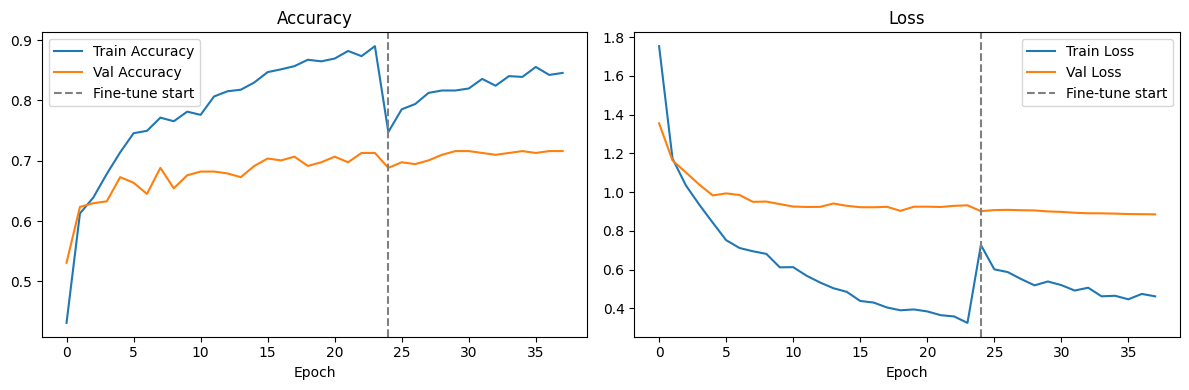


✅ Training complete. All artifacts saved to C:\Users\Lenovo\Desktop\CattleBreedClean\


In [11]:
# 9. Plot training curves
# -----------------------------------------------------------------
def combine_history(h1, h2, key):
    return h1.history[key] + h2.history[key]
 
acc = combine_history(history1, history2, 'accuracy')
val_acc = combine_history(history1, history2, 'val_accuracy')
loss = combine_history(history1, history2, 'loss')
val_loss = combine_history(history1, history2, 'val_loss')
 
plt.figure(figsize=(12, 4))
 
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.axvline(x=len(history1.history['accuracy']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()
 
plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.axvline(x=len(history1.history['loss']), color='gray', linestyle='--', label='Fine-tune start')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()
 
plt.tight_layout()
plt.savefig(r"C:\Users\Lenovo\Desktop\CattleBreedClean\training_curves.png")
plt.show()
 
print("\n✅ Training complete. All artifacts saved to C:\\Users\\Lenovo\\Desktop\\CattleBreedClean\\")
 